<a href="https://colab.research.google.com/github/jannatulferdus182003/MLLab/blob/main/Istanbul_Water_Consumption_Research_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Istanbul Water Consumption Prediction — Research Version 2.0

**Forecast horizons:** next 1, 7, 30 and 365 days  
**Target:** `Total_Consumption`  
**Algorithms:** Linear Regression, Random Forest Regressor, Gradient Boosting Regressor  
**Additional research experiments:** naïve baselines, walk-forward validation, feature ablation, permutation importance, actual-vs-predicted plots and empirical prediction ranges.

> Run the notebook from top to bottom. This notebook preserves the original analysis and forecasting workflow and adds research-oriented experiments. It does not guarantee publication or superior results; conclusions must be based on the actual outputs.
>
> Weekly, monthly and yearly targets mean rolling totals for the next 7, 30 and 365 days after the forecast origin. They are not calendar week/month/year totals.

## Step 1 — Import libraries
Import data-handling, visualization and machine-learning tools.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as pltpltplt

from google.colab import files

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42

## Step 2 — Upload and read the dataset
Upload the Istanbul CSV file. Keep the original filename or update `file_name` below.

In [6]:
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print('Dataset loaded.')
print('Shape:', df.shape)
display(df.head())

Saving Istanbul_BarrageIntakeandConsumption.csv to Istanbul_BarrageIntakeandConsumption.csv
Dataset loaded.
Shape: (4797, 12)


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption
0,1/1/2011,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2096199
1,1/2/2011,0.000,0.000,0.000,0.420,1.370,0.870,0.200,2.260,1.890,1.390,2214668
2,1/3/2011,8.080,10.010,11.640,18.820,9.640,14.720,13.500,8.200,10.370,16.470,2092441
3,1/4/2011,2.780,8.480,7.090,3.420,0.830,4.310,4.300,1.440,1.600,3.990,2096199
4,1/5/2011,0.000,0.780,0.000,0.420,0.000,0.000,0.560,1.150,1.110,0.800,2214668


## Step 3 — Understand the dataset
Inspect columns, data types, sample records and descriptive statistics.

In [7]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('Data type'))
print('\nDataset information:')
df.info()
print('\nNumerical summary:')
display(df.describe().T)

Shape: (4797, 12)

Columns: ['Date', 'Omerli', 'Darlik', 'Elmali', 'Terkos', 'B.Cekmece', 'Sazlidere', 'Alibey', 'Kazandere', 'Pabucdere', 'Istırancalar', 'Total_Consumption']

Data types:


,Data type
Date,object
Omerli,float64
Darlik,float64
Elmali,float64
Terkos,float64
B.Cekmece,float64
Sazlidere,float64
Alibey,float64
Kazandere,float64
Pabucdere,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4797 entries, 0 to 4796
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Date               4797 non-null   object 
 1   Omerli             4797 non-null   float64
 2   Darlik             4797 non-null   float64
 3   Elmali             4797 non-null   float64
 4   Terkos             4797 non-null   float64
 5   B.Cekmece          4797 non-null   float64
 6   Sazlidere          4797 non-null   float64
 7   Alibey             4797 non-null   float64
 8   Kazandere          4797 non-null   float64
 9   Pabucdere          4797 non-null   float64
 10  Istırancalar       4797 non-null   float64
 11  Total_Consumption  4797 non-null   int64  
dtypes: float64(10), int64(1), object(1)
memory usage: 449.8+ KB

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Omerli,"4,797.000",2.075,5.930,0.000,0.000,0.000,0.930,123.530
Darlik,"4,797.000",2.269,6.106,0.000,0.000,0.000,1.200,82.690
Elmali,"4,797.000",1.886,5.596,0.000,0.000,0.000,0.700,95.470
Terkos,"4,797.000",2.411,7.102,0.000,0.000,0.000,1.110,131.280
B.Cekmece,"4,797.000",1.680,5.345,0.000,0.000,0.000,0.400,95.590
Sazlidere,"4,797.000",1.821,6.256,0.000,0.000,0.000,0.500,178.250
Alibey,"4,797.000",2.018,6.105,0.000,0.000,0.000,0.700,119.000
Kazandere,"4,797.000",2.599,8.745,0.000,0.000,0.000,0.550,170.200
Pabucdere,"4,797.000",2.449,8.099,0.000,0.000,0.000,0.430,171.080
Istırancalar,"4,797.000",2.428,7.708,0.000,0.000,0.000,1.000,172.000


## Step 4 — Data quality checks
Check missing values, duplicate rows and zero proportions in reservoir columns. Do not automatically replace zero reservoir values: first confirm from the original source whether zero means no intake or an unrecorded value.

In [8]:
print('Missing values:')
display(df.isna().sum().to_frame('Missing count'))
print('Total missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))

reservoir_columns = [
    'Omerli', 'Darlik', 'Elmali', 'Terkos', 'B.Cekmece',
    'Sazlidere', 'Alibey', 'Kazandere', 'Pabucdere', 'Istırancalar'
]
missing_columns = [c for c in reservoir_columns + ['Date', 'Total_Consumption'] if c not in df.columns]
if missing_columns:
    raise ValueError(f'Required columns not found: {missing_columns}')

print('Zero-value share in reservoir columns:')
display((df[reservoir_columns] == 0).mean().sort_values(ascending=False).to_frame('Zero share'))

Missing values:


,Missing count
Date,0
Omerli,0
Darlik,0
Elmali,0
Terkos,0
B.Cekmece,0
Sazlidere,0
Alibey,0
Kazandere,0
Pabucdere,0


Total missing cells: 0
Duplicate rows: 0
Zero-value share in reservoir columns:


,Zero share
Pabucdere,0.725
B.Cekmece,0.723
Kazandere,0.721
Sazlidere,0.720
Omerli,0.700
Alibey,0.697
Istırancalar,0.692
Elmali,0.690
Terkos,0.684
Darlik,0.673


## Step 5 — Convert dates and sort chronologically
Convert `Date` into datetime format and sort oldest to newest. This order must be preserved for time-series modelling.

In [9]:
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='coerce')
if df['Date'].isna().any():
    raise ValueError('Some Date values could not be parsed. Inspect the original CSV date format.')

df = df.sort_values('Date').reset_index(drop=True)
print('First date:', df['Date'].min())
print('Last date:', df['Date'].max())
display(df.head())

First date: 2011-01-01 00:00:00
Last date: 2024-02-18 00:00:00


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption
0,2011-01-01,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2096199
1,2011-01-02,0.000,0.000,0.000,0.420,1.370,0.870,0.200,2.260,1.890,1.390,2214668
2,2011-01-03,8.080,10.010,11.640,18.820,9.640,14.720,13.500,8.200,10.370,16.470,2092441
3,2011-01-04,2.780,8.480,7.090,3.420,0.830,4.310,4.300,1.440,1.600,3.990,2096199
4,2011-01-05,0.000,0.780,0.000,0.420,0.000,0.000,0.560,1.150,1.110,0.800,2214668


## Step 6 — Check daily date continuity
Identify missing calendar dates and duplicate dates. This cell reports gaps; it does not fabricate missing consumption values.

In [10]:
expected_dates = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
missing_dates = expected_dates.difference(pd.DatetimeIndex(df['Date']))
print('Expected calendar days:', len(expected_dates))
print('Dataset rows:', len(df))
print('Missing calendar dates:', len(missing_dates))
print('Duplicate dates:', int(df['Date'].duplicated().sum()))
if len(missing_dates):
    display(pd.Series(missing_dates[:30], name='Missing date'))

Expected calendar days: 4797
Dataset rows: 4797
Missing calendar dates: 0
Duplicate dates: 0


## Step 7 — Exploratory Data Analysis (EDA)
Plot the historical consumption trend, monthly average consumption and average reservoir intake.

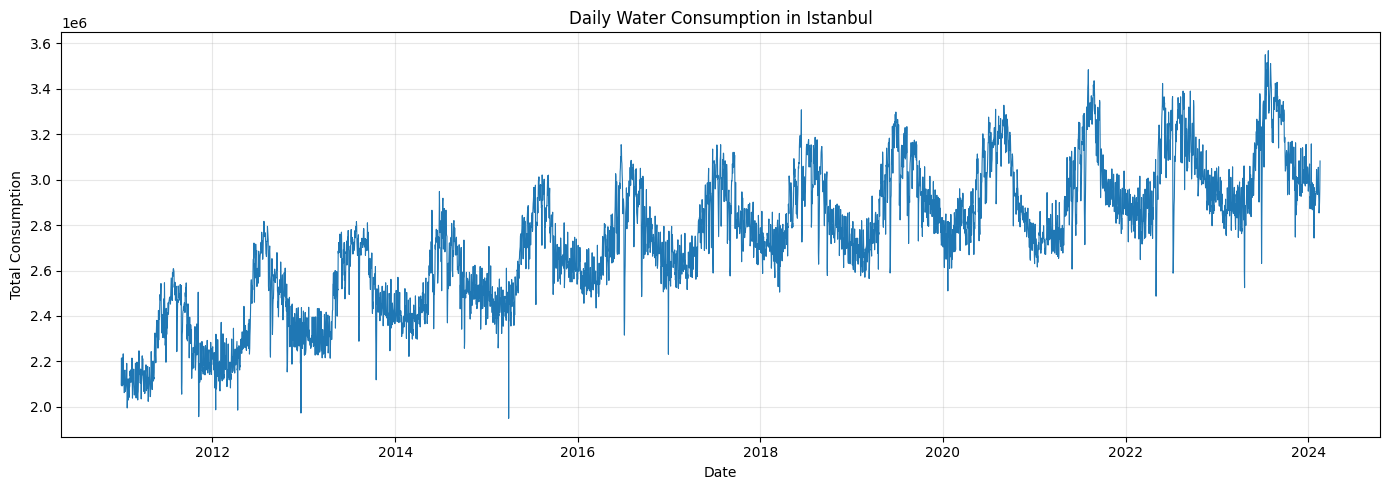

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df['Date'], df['Total_Consumption'], linewidth=0.8)
plt.title('Daily Water Consumption in Istanbul')
plt.xlabel('Date'); plt.ylabel('Total Consumption')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

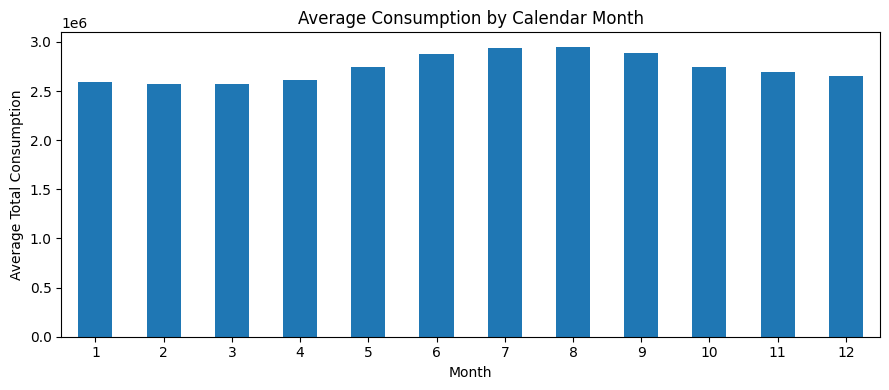

In [13]:
monthly_average = df.groupby(df['Date'].dt.month)['Total_Consumption'].mean()
plt.figure(figsize=(9, 4))
monthly_average.plot(kind='bar')
plt.title('Average Consumption by Calendar Month')
plt.xlabel('Month'); plt.ylabel('Average Total Consumption')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

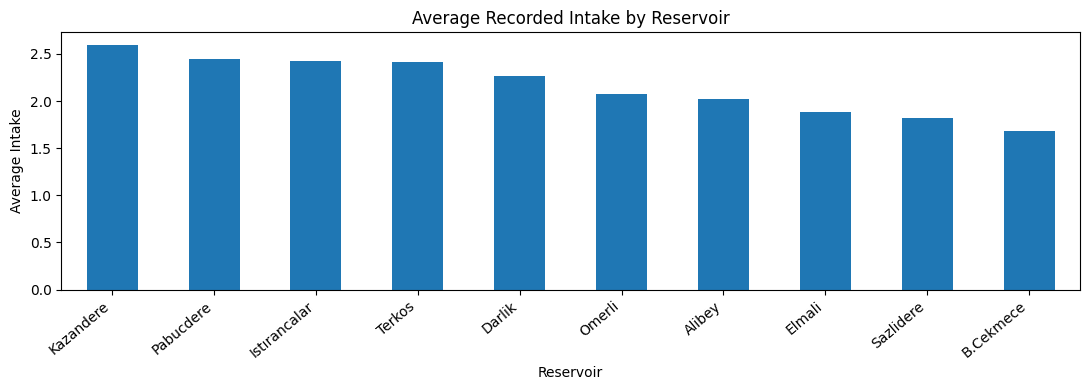

In [14]:
reservoir_average = df[reservoir_columns].mean().sort_values(ascending=False)
plt.figure(figsize=(11, 4))
reservoir_average.plot(kind='bar')
plt.title('Average Recorded Intake by Reservoir')
plt.xlabel('Reservoir'); plt.ylabel('Average Intake')
plt.xticks(rotation=40, ha='right'); plt.tight_layout(); plt.show()

## Step 8 — Descriptive statistical analysis
Calculate mean, median, mode, standard deviation and variance for numerical columns.

In [15]:
numeric_columns = df.select_dtypes(include=np.number).columns
statistics = pd.DataFrame({
    'Mean': df[numeric_columns].mean(),
    'Median': df[numeric_columns].median(),
    'Mode': df[numeric_columns].mode().iloc[0],
    'Standard_Deviation': df[numeric_columns].std(),
    'Variance': df[numeric_columns].var()
})
display(statistics)

,Mean,Median,Mode,Standard_Deviation,Variance
Omerli,2.075,0.000,0.000,5.930,35.167
Darlik,2.269,0.000,0.000,6.106,37.279
Elmali,1.886,0.000,0.000,5.596,31.311
Terkos,2.411,0.000,0.000,7.102,50.445
B.Cekmece,1.680,0.000,0.000,5.345,28.565
Sazlidere,1.821,0.000,0.000,6.256,39.133
Alibey,2.018,0.000,0.000,6.105,37.268
Kazandere,2.599,0.000,0.000,8.745,76.466
Pabucdere,2.449,0.000,0.000,8.099,65.588
Istırancalar,2.428,0.000,0.000,7.708,59.413


## Step 9 — Correlation analysis
Correlation shows linear association, not causation. Use it as an exploratory tool, not proof that one variable causes consumption.

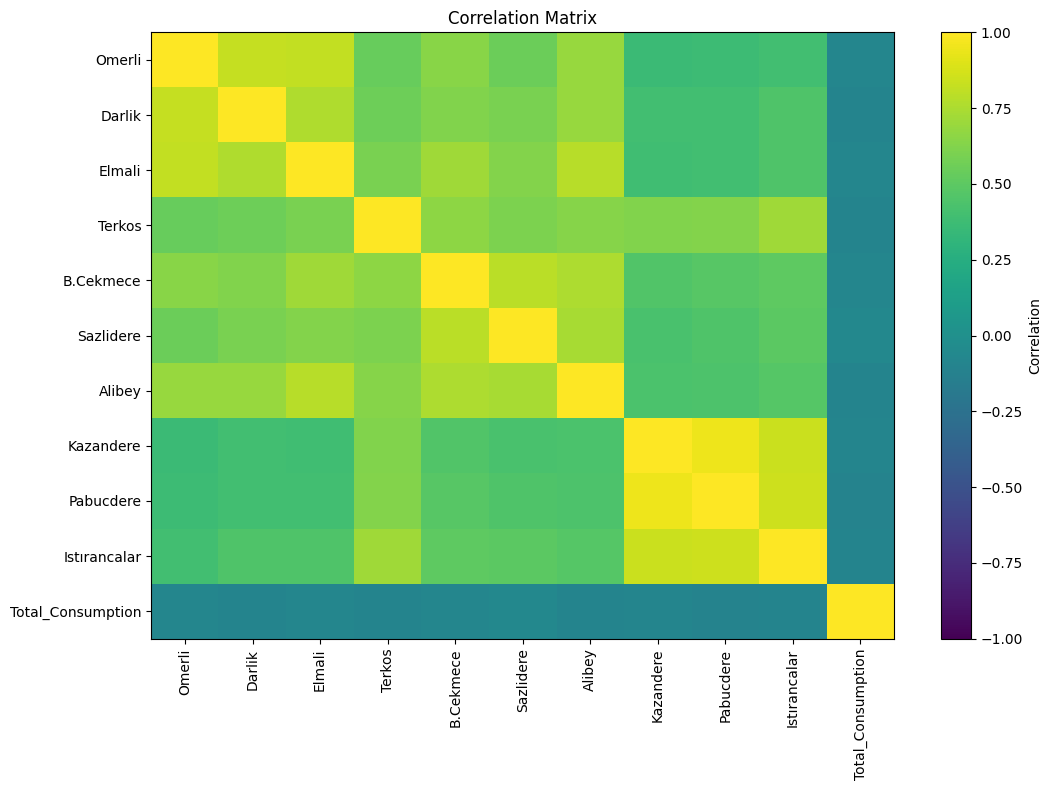

Correlation with Total_Consumption:


,Correlation
Total_Consumption,1.000
Sazlidere,-0.068
Omerli,-0.080
B.Cekmece,-0.081
Elmali,-0.082
Kazandere,-0.088
Darlik,-0.094
Alibey,-0.097
Terkos,-0.099
Istırancalar,-0.100


In [16]:
corr_cols = reservoir_columns + ['Total_Consumption']
corr = df[corr_cols].corr()
plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect='auto', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title('Correlation Matrix')
plt.tight_layout(); plt.show()

print('Correlation with Total_Consumption:')
display(corr['Total_Consumption'].sort_values(ascending=False).to_frame('Correlation'))

## Step 10 — Feature engineering
Create calendar/seasonal variables, current-day measurements, historical lags and trailing averages. Forecast origin is assumed to be after the current date's consumption and reservoir readings are available. If forecasts must be made before same-day measurements are known, remove current-day measurements from the feature list in Step 11.

In [17]:
data = df.copy()

data['Day'] = data['Date'].dt.day
data['Month'] = data['Date'].dt.month
data['DayOfWeek'] = data['Date'].dt.dayofweek
data['DayOfYear'] = data['Date'].dt.dayofyear
data['Trend_Day'] = (data['Date'] - data['Date'].min()).dt.days

data['Year_Sin'] = np.sin(2 * np.pi * data['DayOfYear'] / 365.25)
data['Year_Cos'] = np.cos(2 * np.pi * data['DayOfYear'] / 365.25)
data['Week_Sin'] = np.sin(2 * np.pi * data['DayOfWeek'] / 7)
data['Week_Cos'] = np.cos(2 * np.pi * data['DayOfWeek'] / 7)

for lag in [1, 7, 14, 30, 365]:
    data[f'Consumption_Lag_{lag}'] = data['Total_Consumption'].shift(lag)

for window in [7, 30]:
    data[f'Consumption_Rolling_{window}'] = (
        data['Total_Consumption'].shift(1).rolling(window).mean()
    )

for col in reservoir_columns:
    data[f'{col}_Lag_1'] = data[col].shift(1)
    data[f'{col}_Rolling_7'] = data[col].shift(1).rolling(7).mean()

print('Feature engineering completed.')
display(data.head(8))

Feature engineering completed.


,Date,Omerli,Darlik,Elmali,Terkos,B.Cekmece,Sazlidere,Alibey,Kazandere,Pabucdere,Istırancalar,Total_Consumption,Day,Month,DayOfWeek,DayOfYear,Trend_Day,Year_Sin,Year_Cos,Week_Sin,Week_Cos,Consumption_Lag_1,Consumption_Lag_7,Consumption_Lag_14,Consumption_Lag_30,Consumption_Lag_365,Consumption_Rolling_7,Consumption_Rolling_30,Omerli_Lag_1,Omerli_Rolling_7,Darlik_Lag_1,Darlik_Rolling_7,Elmali_Lag_1,Elmali_Rolling_7,Terkos_Lag_1,Terkos_Rolling_7,B.Cekmece_Lag_1,B.Cekmece_Rolling_7,Sazlidere_Lag_1,Sazlidere_Rolling_7,Alibey_Lag_1,Alibey_Rolling_7,Kazandere_Lag_1,Kazandere_Rolling_7,Pabucdere_Lag_1,Pabucdere_Rolling_7,Istırancalar_Lag_1,Istırancalar_Rolling_7
0,2011-01-01,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2096199,1,1,5,1,0,0.017,1.000,-0.975,-0.223,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-02,0.000,0.000,0.000,0.420,1.370,0.870,0.200,2.260,1.890,1.390,2214668,2,1,6,2,1,0.034,0.999,-0.782,0.623,"2,096,199.000",NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.000,NaN
2,2011-01-03,8.080,10.010,11.640,18.820,9.640,14.720,13.500,8.200,10.370,16.470,2092441,3,1,0,3,2,0.052,0.999,0.000,1.000,"2,214,668.000",NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,0.000,NaN,0.420,NaN,1.370,NaN,0.870,NaN,0.200,NaN,2.260,NaN,1.890,NaN,1.390,NaN
3,2011-01-04,2.780,8.480,7.090,3.420,0.830,4.310,4.300,1.440,1.600,3.990,2096199,4,1,1,4,3,0.069,0.998,0.782,0.623,"2,092,441.000",NaN,NaN,NaN,NaN,NaN,NaN,8.080,NaN,10.010,NaN,11.640,NaN,18.820,NaN,9.640,NaN,14.720,NaN,13.500,NaN,8.200,NaN,10.370,NaN,16.470,NaN
4,2011-01-05,0.000,0.780,0.000,0.420,0.000,0.000,0.560,1.150,1.110,0.800,2214668,5,1,2,5,4,0.086,0.996,0.975,-0.223,"2,096,199.000",NaN,NaN,NaN,NaN,NaN,NaN,2.780,NaN,8.480,NaN,7.090,NaN,3.420,NaN,0.830,NaN,4.310,NaN,4.300,NaN,1.440,NaN,1.600,NaN,3.990,NaN
5,2011-01-06,0.000,3.050,0.700,9.110,0.000,0.640,3.370,1.250,1.600,0.740,2092441,6,1,3,6,5,0.103,0.995,0.434,-0.901,"2,214,668.000",NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.780,NaN,0.000,NaN,0.420,NaN,0.000,NaN,0.000,NaN,0.560,NaN,1.150,NaN,1.110,NaN,0.800,NaN
6,2011-01-07,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2096199,7,1,4,7,6,0.120,0.993,-0.434,-0.901,"2,092,441.000",NaN,NaN,NaN,NaN,NaN,NaN,0.000,NaN,3.050,NaN,0.700,NaN,9.110,NaN,0.000,NaN,0.640,NaN,3.370,NaN,1.250,NaN,1.600,NaN,0.740,NaN
7,2011-01-08,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2170233,8,1,5,8,7,0.137,0.991,-0.975,-0.223,"2,096,199.000","2,096,199.000",NaN,NaN,NaN,"2,128,973.571",NaN,0.000,1.551,0.000,3.189,0.000,2.776,0.000,4.599,0.000,1.691,0.000,2.934,0.000,3.133,0.000,2.043,0.000,2.367,0.000,3.341


## Step 11 — Select input features (X)
The current-day consumption and reservoir values are included under the stated forecast-origin assumption. All lag and rolling features use past values only.

In [18]:
calendar_features = [
    'Day', 'Month', 'DayOfWeek', 'DayOfYear',
    'Year_Sin', 'Year_Cos', 'Week_Sin', 'Week_Cos', 'Trend_Day'
]
consumption_features = [
    'Total_Consumption',
    'Consumption_Lag_1', 'Consumption_Lag_7',
    'Consumption_Lag_14', 'Consumption_Lag_30',
    'Consumption_Lag_365',
    'Consumption_Rolling_7', 'Consumption_Rolling_30'
]
reservoir_features = []
for col in reservoir_columns:
    reservoir_features.extend([f'{col}_Lag_1', f'{col}_Rolling_7'])

features = calendar_features + consumption_features + reservoir_features
print('Number of features:', len(features))
print(features)

Number of features: 37
['Day', 'Month', 'DayOfWeek', 'DayOfYear', 'Year_Sin', 'Year_Cos', 'Week_Sin', 'Week_Cos', 'Trend_Day', 'Total_Consumption', 'Consumption_Lag_1', 'Consumption_Lag_7', 'Consumption_Lag_14', 'Consumption_Lag_30', 'Consumption_Lag_365', 'Consumption_Rolling_7', 'Consumption_Rolling_30', 'Omerli_Lag_1', 'Omerli_Rolling_7', 'Darlik_Lag_1', 'Darlik_Rolling_7', 'Elmali_Lag_1', 'Elmali_Rolling_7', 'Terkos_Lag_1', 'Terkos_Rolling_7', 'B.Cekmece_Lag_1', 'B.Cekmece_Rolling_7', 'Sazlidere_Lag_1', 'Sazlidere_Rolling_7', 'Alibey_Lag_1', 'Alibey_Rolling_7', 'Kazandere_Lag_1', 'Kazandere_Rolling_7', 'Pabucdere_Lag_1', 'Pabucdere_Rolling_7', 'Istırancalar_Lag_1', 'Istırancalar_Rolling_7']


## Step 12 — Create four future-period targets
Each target starts on the day after the forecast-origin date. For example, the weekly target is the sum of the next seven daily observations.

In [19]:
horizons = {'Daily': 1, 'Weekly': 7, 'Monthly': 30, 'Yearly': 365}

for name, days in horizons.items():
    data[f'Target_{name}'] = (
        data['Total_Consumption']
        .shift(-1)
        .rolling(window=days)
        .sum()
        .shift(-(days - 1))
    )

display(data[['Date', 'Total_Consumption',
              'Target_Daily', 'Target_Weekly',
              'Target_Monthly', 'Target_Yearly']].head(10))

,Date,Total_Consumption,Target_Daily,Target_Weekly,Target_Monthly,Target_Yearly
0,2011-01-01,2096199,"2,214,668.000","14,976,849.000","63,332,102.000","824,167,007.000"
1,2011-01-02,2214668,"2,092,441.000","14,995,336.000","63,158,320.000","824,216,681.000"
2,2011-01-03,2092441,"2,096,199.000","15,048,482.000","63,190,712.000","824,339,215.000"
3,2011-01-04,2096199,"2,214,668.000","15,052,091.000","63,180,189.000","824,451,569.000"
4,2011-01-05,2214668,"2,092,441.000","14,947,956.000","63,056,989.000","824,458,833.000"
5,2011-01-06,2092441,"2,096,199.000","14,917,696.000","63,120,616.000","824,531,435.000"
6,2011-01-07,2096199,"2,170,233.000","14,887,341.000","63,161,548.000","824,597,148.000"
7,2011-01-08,2170233,"2,233,155.000","14,874,199.000","63,153,609.000","824,665,707.000"
8,2011-01-09,2233155,"2,145,587.000","14,802,544.000","63,032,242.000","824,580,606.000"
9,2011-01-10,2145587,"2,099,808.000","14,741,483.000","62,994,410.000","824,563,203.000"


## Step 13 — Define machine-learning algorithms
Compare three regression algorithms. XGBoost is not included.

In [20]:
def create_models():
    return {
        'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
        'Random Forest': RandomForestRegressor(
            n_estimators=150, max_depth=15, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ),
        'Gradient Boosting': GradientBoostingRegressor(
            n_estimators=150, learning_rate=0.05, max_depth=2,
            random_state=RANDOM_STATE
        )
    }

## Step 14 — Chronological train, validation and test split
Use 70% training, 15% validation and 15% testing in date order. A gap equal to each forecast horizon is left at split boundaries so target windows do not overlap across the partitions.

In [21]:
def make_temporal_splits(model_data, horizon):
    n = len(model_data)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train = model_data.iloc[:max(0, train_end - horizon)].copy()
    validation = model_data.iloc[train_end:max(train_end, val_end - horizon)].copy()
    test = model_data.iloc[val_end:].copy()

    if min(len(train), len(validation), len(test)) == 0:
        raise ValueError('Not enough rows for this horizon and split.')

    return train, validation, test

## Step 15 — Train, validate and test the three models
Select the algorithm with the lowest validation RMSE. Refit it on the training plus validation records and evaluate it once on the held-out test records.

In [22]:
validation_results = []
test_results = []
best_models = {}
test_predictions = {}
test_actuals = {}
test_dates = {}
validation_residuals = {}

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)
    train_data, val_data, test_data = make_temporal_splits(model_data, days)

    X_train, y_train = train_data[features], train_data[target]
    X_val, y_val = val_data[features], val_data[target]
    X_test, y_test = test_data[features], test_data[target]

    print('\n' + '=' * 60)
    print(name, 'forecast | rows:', len(train_data), len(val_data), len(test_data))

    val_scores = {}
    fitted_validation_models = {}

    for model_name, model in create_models().items():
        model.fit(X_train, y_train)
        val_pred = model.predict(X_val)
        mae = mean_absolute_error(y_val, val_pred)
        rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        r2 = r2_score(y_val, val_pred)
        val_scores[model_name] = rmse
        fitted_validation_models[model_name] = model

        validation_results.append({
            'Forecast': name, 'Algorithm': model_name,
            'Validation_MAE': mae, 'Validation_RMSE': rmse,
            'Validation_R2': r2
        })

    selected_name = min(val_scores, key=val_scores.get)
    selected_validation_model = fitted_validation_models[selected_name]
    val_residual = y_val.to_numpy() - selected_validation_model.predict(X_val)
    validation_residuals[name] = val_residual

    # Refit selected algorithm on train + validation only
    train_val = pd.concat([train_data, val_data], axis=0)
    final_eval_model = create_models()[selected_name]
    final_eval_model.fit(train_val[features], train_val[target])
    test_pred = final_eval_model.predict(X_test)

    test_mae = mean_absolute_error(y_test, test_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    test_r2 = r2_score(y_test, test_pred)

    best_models[name] = selected_name
    test_predictions[name] = test_pred
    test_actuals[name] = y_test.to_numpy()
    test_dates[name] = test_data['Date'].to_numpy()

    test_results.append({
        'Forecast': name, 'Selected_Algorithm': selected_name,
        'Test_MAE': test_mae, 'Test_RMSE': test_rmse, 'Test_R2': test_r2,
        'Test_Rows': len(test_data)
    })

    print('Selected:', selected_name)
    print(f'Test MAE={test_mae:,.3f} | RMSE={test_rmse:,.3f} | R2={test_r2:.4f}')

validation_results_df = pd.DataFrame(validation_results)
test_results_df = pd.DataFrame(test_results)

print('\nValidation comparison:')
display(validation_results_df.sort_values(['Forecast', 'Validation_RMSE']))
print('\nSelected-model test results:')
display(test_results_df)


Daily forecast | rows: 3100 664 665
Selected: Linear Regression
Test MAE=58,851.082 | RMSE=83,849.092 | R2=0.7851

Weekly forecast | rows: 3090 657 664
Selected: Linear Regression
Test MAE=375,089.252 | RMSE=546,300.180 | R2=0.7675

Monthly forecast | rows: 3051 630 661
Selected: Linear Regression
Test MAE=1,571,750.461 | RMSE=2,045,600.495 | R2=0.7885

Yearly forecast | rows: 2481 245 611
Selected: Gradient Boosting
Test MAE=38,481,512.681 | RMSE=38,970,785.285 | R2=-35.2176

Validation comparison:


,Forecast,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2
0,Daily,Linear Regression,"53,089.744","71,508.618",0.858
1,Daily,Random Forest,"67,484.247","90,967.501",0.770
2,Daily,Gradient Boosting,"67,737.958","96,112.316",0.743
6,Monthly,Linear Regression,"1,958,391.585","2,317,483.557",0.797
7,Monthly,Random Forest,"2,280,100.022","3,029,066.895",0.654
8,Monthly,Gradient Boosting,"2,275,723.702","3,131,183.075",0.630
3,Weekly,Linear Regression,"396,617.764","497,946.231",0.840
5,Weekly,Gradient Boosting,"511,139.597","764,312.522",0.624
4,Weekly,Random Forest,"534,458.213","779,710.491",0.609
11,Yearly,Gradient Boosting,"18,663,616.100","18,846,882.313",-48.252



Selected-model test results:


,Forecast,Selected_Algorithm,Test_MAE,Test_RMSE,Test_R2,Test_Rows
0,Daily,Linear Regression,"58,851.082","83,849.092",0.785,665
1,Weekly,Linear Regression,"375,089.252","546,300.180",0.767,664
2,Monthly,Linear Regression,"1,571,750.461","2,045,600.495",0.788,661
3,Yearly,Gradient Boosting,"38,481,512.681","38,970,785.285",-35.218,611


## Step 16 — Baseline comparison
A machine-learning model should be compared with simple forecasting rules. The baseline below predicts each future-period total using the recent average daily consumption multiplied by the horizon. This is a simple benchmark, not a trained ML algorithm.

In [23]:
baseline_results = []

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)
    _, _, test_data = make_temporal_splits(model_data, days)

    # Naive level: use the most recent observed daily consumption as daily rate.
    # Seasonal/recent-average baseline: use mean of the latest 7 or 30 observed days.
    actual = test_data[target].to_numpy()
    recent7 = data['Total_Consumption'].shift(1).rolling(7).mean()
    recent30 = data['Total_Consumption'].shift(1).rolling(30).mean()

    origin_idx = test_data.index
    naive_pred = test_data['Total_Consumption'].to_numpy() * days
    avg7_pred = recent7.loc[origin_idx].to_numpy() * days
    avg30_pred = recent30.loc[origin_idx].to_numpy() * days

    for baseline_name, pred in [
        ('Last-day rate baseline', naive_pred),
        ('Previous-7-day average baseline', avg7_pred),
        ('Previous-30-day average baseline', avg30_pred)
    ]:
        valid = np.isfinite(pred)
        baseline_results.append({
            'Forecast': name,
            'Baseline': baseline_name,
            'MAE': mean_absolute_error(actual[valid], pred[valid]),
            'RMSE': np.sqrt(mean_squared_error(actual[valid], pred[valid])),
            'R2': r2_score(actual[valid], pred[valid])
        })

baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df)

,Forecast,Baseline,MAE,RMSE,R2
0,Daily,Last-day rate baseline,"65,379.839","90,867.786",0.748
1,Daily,Previous-7-day average baseline,"118,260.047","160,645.404",0.211
2,Daily,Previous-30-day average baseline,"111,179.848","151,928.896",0.294
3,Weekly,Last-day rate baseline,"527,332.747","749,705.767",0.562
4,Weekly,Previous-7-day average baseline,"710,301.005","986,734.411",0.241
5,Weekly,Previous-30-day average baseline,"654,305.373","922,047.636",0.338
6,Monthly,Last-day rate baseline,"2,646,280.867","3,712,173.979",0.303
7,Monthly,Previous-7-day average baseline,"2,805,763.134","3,988,692.796",0.196
8,Monthly,Previous-30-day average baseline,"2,835,780.808","3,962,254.727",0.206
9,Yearly,Last-day rate baseline,"56,961,059.633","67,344,666.405",-107.155


## Step 17 — Walk-forward validation (expanding window)
This experiment repeats validation at multiple chronological cutoffs. Each fold trains on earlier records and validates on a later block. The gap prevents the future target windows at the boundary from overlapping. It is computationally heavier than one split.

In [24]:
walk_forward_rows = []

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)

    # Keep a final untouched test segment aside; CV is run on earlier data.
    pretest_end = int(len(model_data) * 0.85)
    development = model_data.iloc[:pretest_end].copy().reset_index(drop=True)

    splitter = TimeSeriesSplit(n_splits=4, gap=days)

    for model_name, model_template in create_models().items():
        fold_number = 0
        for train_idx, val_idx in splitter.split(development):
            fold_number += 1
            train_fold = development.iloc[train_idx]
            val_fold = development.iloc[val_idx]

            model = create_models()[model_name]
            model.fit(train_fold[features], train_fold[target])
            pred = model.predict(val_fold[features])

            walk_forward_rows.append({
                'Forecast': name,
                'Algorithm': model_name,
                'Fold': fold_number,
                'Validation_MAE': mean_absolute_error(val_fold[target], pred),
                'Validation_RMSE': np.sqrt(mean_squared_error(val_fold[target], pred)),
                'Validation_R2': r2_score(val_fold[target], pred)
            })

walk_forward_df = pd.DataFrame(walk_forward_rows)
display(walk_forward_df)

walk_forward_summary = (
    walk_forward_df.groupby(['Forecast', 'Algorithm'])[
        ['Validation_MAE', 'Validation_RMSE', 'Validation_R2']
    ].mean().reset_index()
)
print('Average walk-forward performance across folds:')
display(walk_forward_summary.sort_values(['Forecast', 'Validation_RMSE']))

,Forecast,Algorithm,Fold,Validation_MAE,Validation_RMSE,Validation_R2
0,Daily,Linear Regression,1,"57,783.121","80,259.354",0.770
1,Daily,Linear Regression,2,"56,961.613","79,218.929",0.752
2,Daily,Linear Regression,3,"57,478.304","78,069.864",0.782
3,Daily,Linear Regression,4,"56,111.841","74,197.248",0.837
4,Daily,Random Forest,1,"96,580.298","125,872.427",0.435
5,Daily,Random Forest,2,"82,539.538","105,867.753",0.557
6,Daily,Random Forest,3,"74,528.396","95,770.264",0.671
7,Daily,Random Forest,4,"67,385.423","90,030.393",0.761
8,Daily,Gradient Boosting,1,"106,055.562","157,372.689",0.117
9,Daily,Gradient Boosting,2,"70,578.589","94,930.308",0.644


Average walk-forward performance across folds:


,Forecast,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2
1,Daily,Linear Regression,"57,083.720","77,936.349",0.785
2,Daily,Random Forest,"80,258.414","104,385.209",0.606
0,Daily,Gradient Boosting,"77,639.115","108,124.439",0.557
4,Monthly,Linear Regression,"1,692,403.992","2,070,045.561",0.762
3,Monthly,Gradient Boosting,"2,026,196.157","2,598,671.833",0.621
5,Monthly,Random Forest,"2,468,899.855","3,132,326.349",0.460
7,Weekly,Linear Regression,"393,631.850","517,259.445",0.767
6,Weekly,Gradient Boosting,"494,123.902","667,328.434",0.603
8,Weekly,Random Forest,"607,795.492","798,558.953",0.434
10,Yearly,Linear Regression,"23,705,079.531","25,071,874.521",-9.184


## Step 18 — Compare validation, baseline and test results
Use the same metric and horizon when comparing. A smaller MAE/RMSE is better; R² closer to 1 is generally better. Negative R² means the model performed worse than predicting the test-set mean.

In [26]:
for horizon_name in horizons:
    print('\n', horizon_name, '— ML validation results')
    display(validation_results_df[validation_results_df['Forecast'] == horizon_name]
            .sort_values('Validation_RMSE'))

    print(horizon_name, '— baseline test results')
    display(baseline_results_df[baseline_results_df['Forecast'] == horizon_name])

print('Selected ML model test results:')
display(test_results_df)


 Daily — ML validation results


,Forecast,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2
0,Daily,Linear Regression,"53,089.744","71,508.618",0.858
1,Daily,Random Forest,"67,484.247","90,967.501",0.770
2,Daily,Gradient Boosting,"67,737.958","96,112.316",0.743


Daily — baseline test results


,Forecast,Baseline,MAE,RMSE,R2
0,Daily,Last-day rate baseline,"65,379.839","90,867.786",0.748
1,Daily,Previous-7-day average baseline,"118,260.047","160,645.404",0.211
2,Daily,Previous-30-day average baseline,"111,179.848","151,928.896",0.294



 Weekly — ML validation results


,Forecast,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2
3,Weekly,Linear Regression,"396,617.764","497,946.231",0.840
5,Weekly,Gradient Boosting,"511,139.597","764,312.522",0.624
4,Weekly,Random Forest,"534,458.213","779,710.491",0.609


... (8 outputs left out)

Yearly — baseline test results


,Forecast,Baseline,MAE,RMSE,R2
9,Yearly,Last-day rate baseline,"56,961,059.633","67,344,666.405",-107.155
10,Yearly,Previous-7-day average baseline,"65,179,398.909","72,666,272.830",-124.924
11,Yearly,Previous-30-day average baseline,"60,996,102.427","68,830,668.274",-111.981


Selected ML model test results:


,Forecast,Selected_Algorithm,Test_MAE,Test_RMSE,Test_R2,Test_Rows
0,Daily,Linear Regression,"58,851.082","83,849.092",0.785,665
1,Weekly,Linear Regression,"375,089.252","546,300.180",0.767,664
2,Monthly,Linear Regression,"1,571,750.461","2,045,600.495",0.788,661
3,Yearly,Gradient Boosting,"38,481,512.681","38,970,785.285",-35.218,611


## Step 19 — Actual vs predicted plots
These graphs compare held-out test targets with predictions from the selected algorithm. Weekly/monthly/yearly targets are period totals associated with each forecast-origin date.

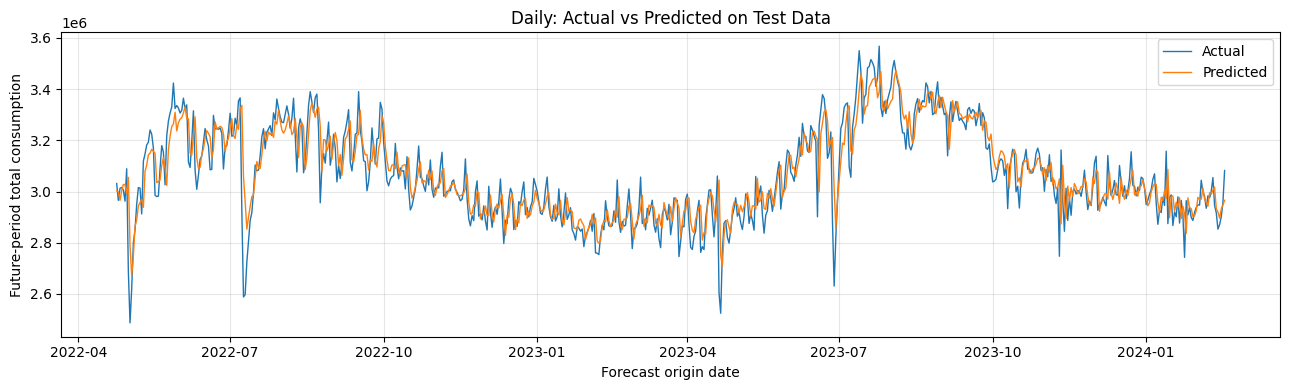

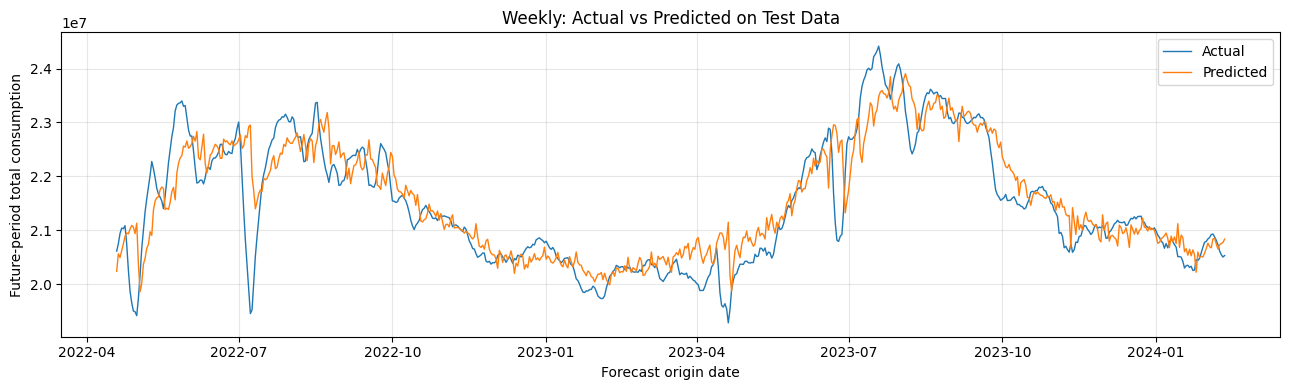

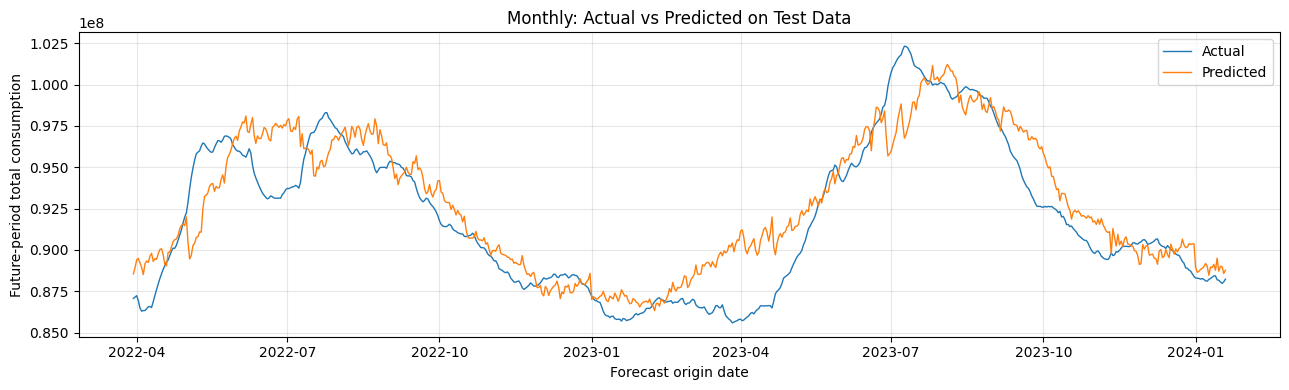

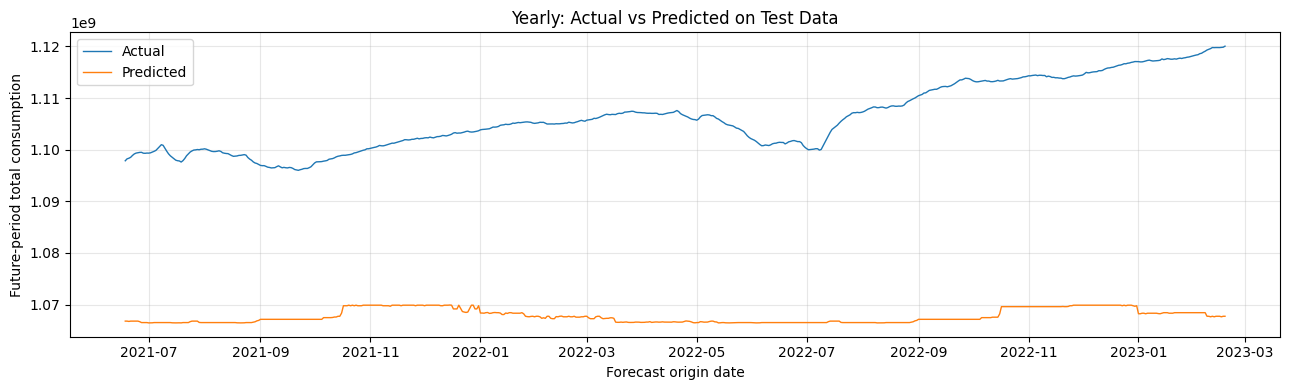

In [27]:
for name in horizons:
    plt.figure(figsize=(13, 4))
    plt.plot(test_dates[name], test_actuals[name], label='Actual', linewidth=1)
    plt.plot(test_dates[name], test_predictions[name], label='Predicted', linewidth=1)
    plt.title(f'{name}: Actual vs Predicted on Test Data')
    plt.xlabel('Forecast origin date')
    plt.ylabel('Future-period total consumption')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## Step 20 — Feature ablation study
Ablation checks whether groups of features add value. For each horizon, compare calendar-only, calendar+consumption-history, and calendar+consumption+reservoir features. Use the same chronological split and the selected algorithm for that horizon. Interpret this as an experiment; do not claim a feature group is useful unless the scores support it.

In [28]:
feature_groups = {
    'Calendar only': calendar_features,
    'Calendar + consumption history': calendar_features + consumption_features,
    'Calendar + consumption + reservoir': calendar_features + consumption_features + reservoir_features
}

ablation_rows = []

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)
    train_data, val_data, test_data = make_temporal_splits(model_data, days)
    chosen_algorithm = best_models[name]

    for group_name, group_features in feature_groups.items():
        model = create_models()[chosen_algorithm]
        model.fit(train_data[group_features], train_data[target])
        val_pred = model.predict(val_data[group_features])

        ablation_rows.append({
            'Forecast': name,
            'Feature_Set': group_name,
            'Algorithm': chosen_algorithm,
            'Validation_MAE': mean_absolute_error(val_data[target], val_pred),
            'Validation_RMSE': np.sqrt(mean_squared_error(val_data[target], val_pred)),
            'Validation_R2': r2_score(val_data[target], val_pred)
        })

ablation_df = pd.DataFrame(ablation_rows)
display(ablation_df.sort_values(['Forecast', 'Validation_RMSE']))

,Forecast,Feature_Set,Algorithm,Validation_MAE,Validation_RMSE,Validation_R2
1,Daily,Calendar + consumption history,Linear Regression,"52,766.778","71,053.461",0.859
2,Daily,Calendar + consumption + reservoir,Linear Regression,"53,089.744","71,508.618",0.858
0,Daily,Calendar only,Linear Regression,"120,926.888","145,691.519",0.409
7,Monthly,Calendar + consumption history,Linear Regression,"1,927,352.711","2,294,172.421",0.801
8,Monthly,Calendar + consumption + reservoir,Linear Regression,"1,958,391.585","2,317,483.557",0.797
6,Monthly,Calendar only,Linear Regression,"3,274,945.837","3,700,259.414",0.483
4,Weekly,Calendar + consumption history,Linear Regression,"388,168.227","491,879.682",0.844
5,Weekly,Calendar + consumption + reservoir,Linear Regression,"396,617.764","497,946.231",0.840
3,Weekly,Calendar only,Linear Regression,"797,166.211","918,427.484",0.457
11,Yearly,Calendar + consumption + reservoir,Gradient Boosting,"18,663,616.100","18,846,882.313",-48.252


## Step 21 — Permutation feature importance
Permutation importance measures how much a model's validation score worsens when one feature is shuffled. It describes predictive usefulness in this fitted model; it does not prove causation. This can take some time.

Daily — top 15 features


,Feature,Importance_Mean,Importance_Std
3,DayOfYear,"206,111.457","5,674.740"
1,Month,"197,955.046","3,710.318"
9,Total_Consumption,"116,067.368","2,257.846"
16,Consumption_Rolling_30,"27,709.557","1,372.803"
15,Consumption_Rolling_7,"17,041.744","1,249.049"
5,Year_Cos,"10,654.534",354.505
0,Day,"2,923.955",822.300
11,Consumption_Lag_7,"1,870.217",746.086
34,Pabucdere_Rolling_7,"1,730.932",332.034
31,Kazandere_Lag_1,"1,669.747",301.437


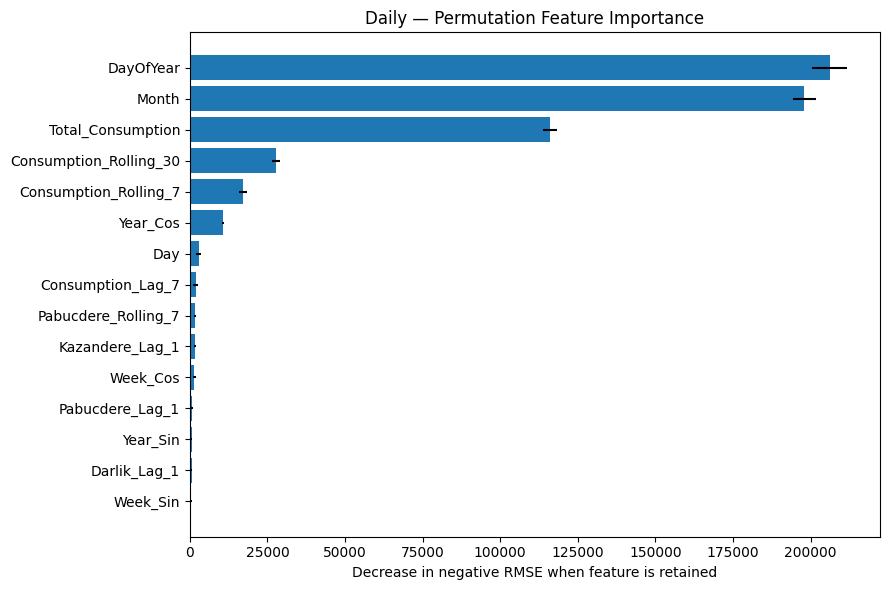

Weekly — top 15 features


,Feature,Importance_Mean,Importance_Std
3,DayOfYear,"3,643,552.147","42,290.957"
1,Month,"3,512,455.793","61,287.295"
9,Total_Consumption,"315,425.183","5,705.649"
16,Consumption_Rolling_30,"265,916.387","6,638.256"
5,Year_Cos,"223,514.129","14,426.775"
15,Consumption_Rolling_7,"99,582.651","1,670.038"
0,Day,"81,020.712","3,478.365"
34,Pabucdere_Rolling_7,"15,023.164","2,688.867"
8,Trend_Day,"8,473.013","4,406.697"
10,Consumption_Lag_1,"7,838.475",527.908


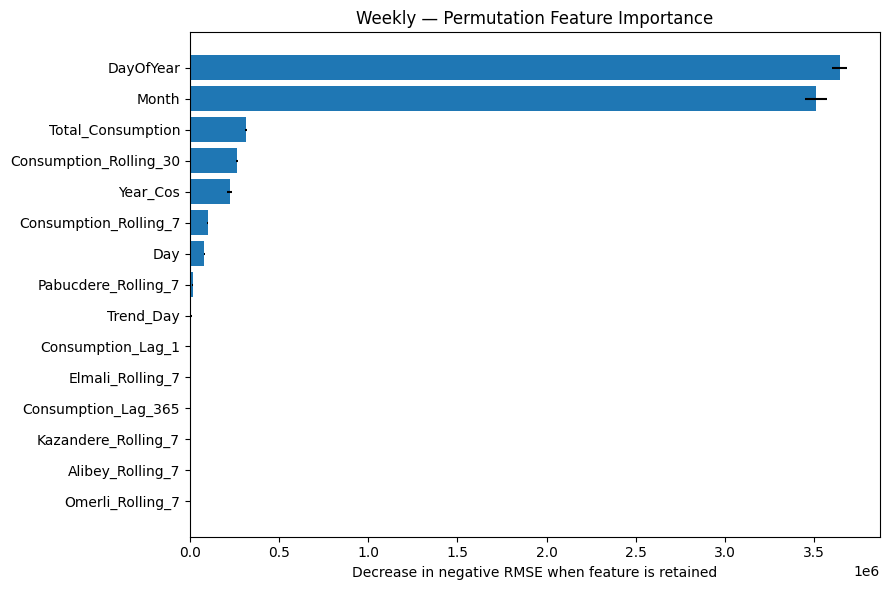

Monthly — top 15 features


,Feature,Importance_Mean,Importance_Std
3,DayOfYear,"9,338,048.711","213,592.723"
1,Month,"8,570,796.194","137,654.981"
5,Year_Cos,"1,937,172.496","45,223.057"
16,Consumption_Rolling_30,"885,849.814","23,864.178"
9,Total_Consumption,"397,353.880","16,276.822"
15,Consumption_Rolling_7,"351,088.763","12,402.390"
0,Day,"194,727.283","18,524.114"
18,Omerli_Rolling_7,"103,962.115","18,561.781"
14,Consumption_Lag_365,"91,443.711","3,982.761"
8,Trend_Day,"81,949.548","10,512.916"


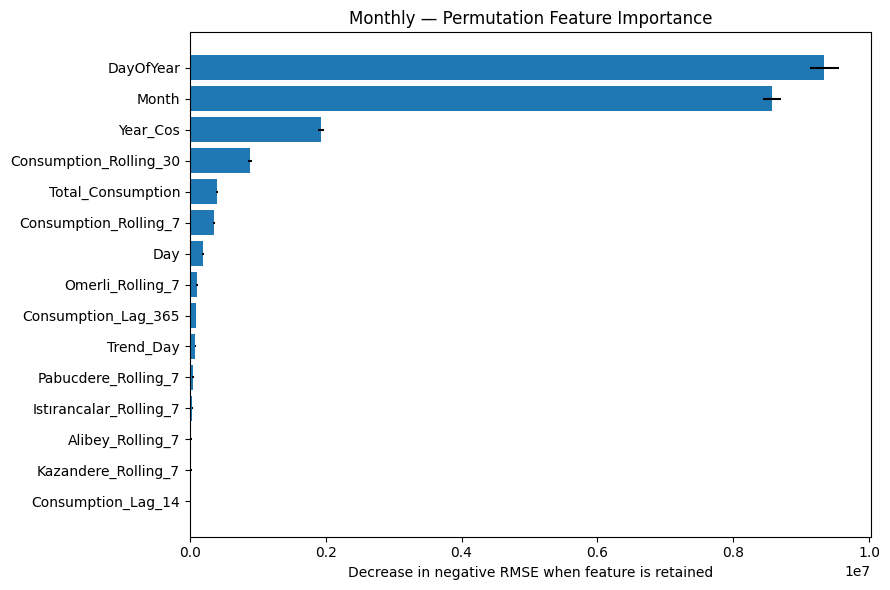

Yearly — top 15 features


,Feature,Importance_Mean,Importance_Std
4,Year_Sin,"14,786.390",812.209
3,DayOfYear,"1,723.994",245.491
13,Consumption_Lag_30,669.674,164.171
2,DayOfWeek,0.000,0.000
0,Day,0.000,0.000
1,Month,0.000,0.000
5,Year_Cos,0.000,0.000
7,Week_Cos,0.000,0.000
6,Week_Sin,0.000,0.000
9,Total_Consumption,0.000,0.000


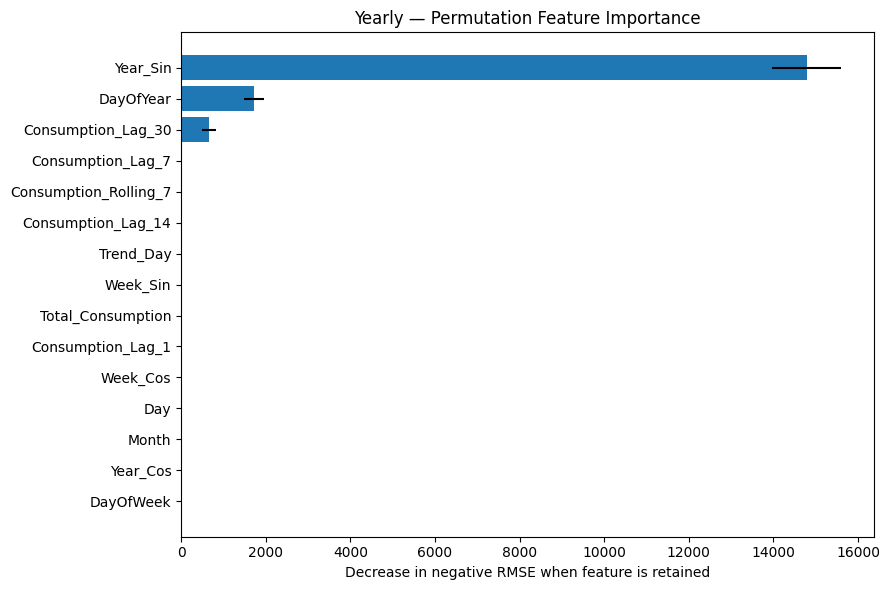

In [29]:
importance_tables = {}

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)
    train_data, val_data, _ = make_temporal_splits(model_data, days)

    model = create_models()[best_models[name]]
    model.fit(train_data[features], train_data[target])

    # Use a reproducible subset if validation is large.
    val_sample = val_data.sample(
        n=min(500, len(val_data)), random_state=RANDOM_STATE
    )

    result = permutation_importance(
        model,
        val_sample[features],
        val_sample[target],
        scoring='neg_root_mean_squared_error',
        n_repeats=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    importance = pd.DataFrame({
        'Feature': features,
        'Importance_Mean': result.importances_mean,
        'Importance_Std': result.importances_std
    }).sort_values('Importance_Mean', ascending=False)

    importance_tables[name] = importance
    print(name, '— top 15 features')
    display(importance.head(15))

    top = importance.head(15).sort_values('Importance_Mean')
    plt.figure(figsize=(9, 6))
    plt.barh(top['Feature'], top['Importance_Mean'], xerr=top['Importance_Std'])
    plt.title(f'{name} — Permutation Feature Importance')
    plt.xlabel('Decrease in negative RMSE when feature is retained')
    plt.tight_layout()
    plt.show()

## Step 22 — Empirical prediction-error range
The following is an approximate empirical range based on validation residual quantiles. It is not a guaranteed or formally calibrated prediction interval. Its coverage should be checked on a separate test set before using it as an uncertainty claim.

In [32]:
uncertainty_rows = []

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy().reset_index(drop=True)
    train_data, val_data, _ = make_temporal_splits(model_data, days)

    model = create_models()[best_models[name]]
    model.fit(train_data[features], train_data[target])
    val_pred = model.predict(val_data[features])
    residuals = val_data[target].to_numpy() - val_pred

    lower_error, upper_error = np.quantile(residuals, [0.05, 0.95])

    uncertainty_rows.append({
        'Forecast': name,
        'Residual_5th_Percentile': lower_error,
        'Residual_95th_Percentile': upper_error,
        'Validation_Residual_MAE': np.mean(np.abs(residuals))
    })

uncertainty_df = pd.DataFrame(uncertainty_rows)
display(uncertainty_df)

,Forecast,Residual_5th_Percentile,Residual_95th_Percentile,Validation_Residual_MAE
0,Daily,"-124,761.050","99,025.817","53,089.744"
1,Weekly,"-844,413.116","565,521.176","396,617.764"
2,Monthly,"-4,078,043.589","2,278,880.633","1,958,391.585"
3,Yearly,"14,707,798.603","22,146,998.655","18,663,616.100"


## Step 23 — Refit selected models using all labeled historical records
After model evaluation, refit each selected algorithm on every row where that horizon's target is known. The earlier held-out test metrics remain the reported evaluation results.

In [33]:
final_models = {}

for name, days in horizons.items():
    target = f'Target_{name}'
    model_data = data.dropna(subset=features + [target]).copy()

    final_model = create_models()[best_models[name]]
    final_model.fit(model_data[features], model_data[target])
    final_models[name] = final_model

    print(f'{name}: final model fitted with {best_models[name]}')

Daily: final model fitted with Linear Regression
Weekly: final model fitted with Linear Regression
Monthly: final model fitted with Linear Regression
Yearly: final model fitted with Gradient Boosting


## Step 24 — Generate final forecasts
The latest feature-complete historical date is the forecast origin. The next calendar day is the first day of each forecast horizon.

In [34]:
latest_rows = data.dropna(subset=features).copy()
latest_row = latest_rows.tail(1)
forecast_origin = latest_row['Date'].iloc[0]
forecast_start = forecast_origin + pd.Timedelta(days=1)

predictions = {}
forecast_rows = []

for name, days in horizons.items():
    predicted_total = float(final_models[name].predict(latest_row[features])[0])
    predictions[name] = predicted_total

    forecast_rows.append({
        'Forecast': name,
        'Horizon_Days': days,
        'Forecast_Origin': forecast_origin.date(),
        'Forecast_Start': forecast_start.date(),
        'Forecast_End': (forecast_origin + pd.Timedelta(days=days)).date(),
        'Predicted_Total_Consumption': predicted_total,
        'Average_Per_Day': predicted_total / days
    })

print('Forecast origin:', forecast_origin.date())
print('Forecast starts:', forecast_start.date())

final_prediction_table = pd.DataFrame(forecast_rows)
display(final_prediction_table.round(3))

Forecast origin: 2024-02-18
Forecast starts: 2024-02-19


,Forecast,Horizon_Days,Forecast_Origin,Forecast_Start,Forecast_End,Predicted_Total_Consumption,Average_Per_Day
0,Daily,1,2024-02-18,2024-02-19,2024-02-19,"3,014,398.320","3,014,398.320"
1,Weekly,7,2024-02-18,2024-02-19,2024-02-25,"20,820,793.966","2,974,399.138"
2,Monthly,30,2024-02-18,2024-02-19,2024-03-19,"89,101,444.817","2,970,048.161"
3,Yearly,365,2024-02-18,2024-02-19,2025-02-17,"1,117,084,571.745","3,060,505.676"


## Step 25 — Plot final forecast totals and daily averages
Because forecast horizons have different lengths, the daily-average chart is useful for comparing average consumption levels.

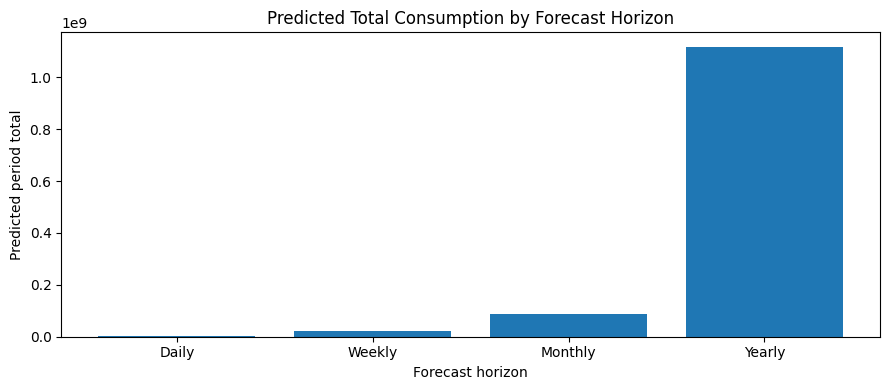

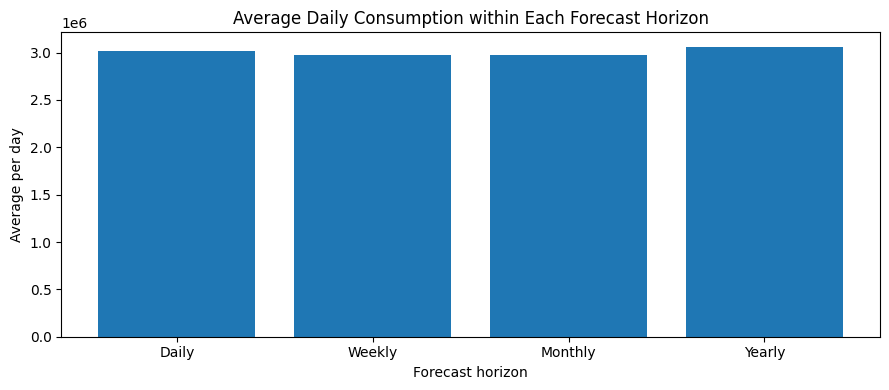

In [35]:
plt.figure(figsize=(9, 4))
plt.bar(final_prediction_table['Forecast'],
        final_prediction_table['Predicted_Total_Consumption'])
plt.title('Predicted Total Consumption by Forecast Horizon')
plt.xlabel('Forecast horizon'); plt.ylabel('Predicted period total')
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4))
plt.bar(final_prediction_table['Forecast'],
        final_prediction_table['Average_Per_Day'])
plt.title('Average Daily Consumption within Each Forecast Horizon')
plt.xlabel('Forecast horizon'); plt.ylabel('Average per day')
plt.tight_layout(); plt.show()

## Step 26 — Save all important results
Save the final forecasts, validation metrics, test metrics, walk-forward results, baseline comparison, ablation results, uncertainty summary and feature importance tables.

In [36]:
final_prediction_table.to_csv('Istanbul_Final_Forecasts.csv', index=False)
validation_results_df.to_csv('Istanbul_Validation_Results.csv', index=False)
test_results_df.to_csv('Istanbul_Test_Results.csv', index=False)
walk_forward_df.to_csv('Istanbul_Walk_Forward_Results.csv', index=False)
baseline_results_df.to_csv('Istanbul_Baseline_Comparison.csv', index=False)
ablation_df.to_csv('Istanbul_Feature_Ablation.csv', index=False)
uncertainty_df.to_csv('Istanbul_Empirical_Error_Ranges.csv', index=False)

for name, table in importance_tables.items():
    table.to_csv(f'Istanbul_{name}_Feature_Importance.csv', index=False)

print('All result files have been saved.')

All result files have been saved.


In [37]:
result_files = [
    'Istanbul_Final_Forecasts.csv',
    'Istanbul_Validation_Results.csv',
    'Istanbul_Test_Results.csv',
    'Istanbul_Walk_Forward_Results.csv',
    'Istanbul_Baseline_Comparison.csv',
    'Istanbul_Feature_Ablation.csv',
    'Istanbul_Empirical_Error_Ranges.csv'
]

for result_file in result_files:
    files.download(result_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (4 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 27 — Research interpretation checklist

Before writing a report or paper, answer these questions from the notebook's actual outputs:

1. Did any ML model outperform all simple baselines for each horizon?
2. Which algorithm performed best on validation, and how did it perform on the untouched test set?
3. Were results consistent across the walk-forward folds?
4. Did reservoir features improve validation performance in the ablation study?
5. Which features had the largest permutation importance?
6. Why is the yearly horizon more difficult? Does it have enough independent historical periods?
7. What does a negative test R² mean for the relevant horizon?
8. What is the measurement unit of `Total_Consumption`, according to the original dataset documentation?
9. What do zero reservoir readings represent in the source data?
10. Are the forecast-origin assumptions realistic for the intended real-world use?

### Limitations to disclose

- The dataset ends on the last date printed in Step 5; forecasts do not automatically represent the current year.
- Confirm the source, licence, measurement units and meaning of zero values from the original data documentation.
- The notebook assumes current-day consumption and reservoir readings are available at the forecast origin.
- The empirical error ranges are exploratory and must not be described as calibrated confidence intervals without a separate coverage evaluation.
- A model's predictive feature importance does not establish causation.
- Research novelty requires a literature review. More experiments alone do not establish a novel contribution.